Leave-one-source-out (LOSO) BiLSTM

In [1]:
import json
import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from tensorflow.keras import callbacks, layers, models
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

SEED = 42

SPLITS_ROOT = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")
WEIGHTS_ROOT = Path("../../weights")
RESULTS_DIR = Path("../../../results/lstm/loso")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)
LABEL_ORDER = list(label_encoder.classes_)

SOURCES = ["df1", "df5"]
print("Folds:", SOURCES)

VOCAB_SIZE = 20000
EMBEDDING_DIM = 128
LSTM_UNITS = 128
DROPOUT = 0.3
RECURRENT_DROPOUT = 0.0
LEARNING_RATE = 1e-3
BATCH_SIZE = 64
EPOCHS = 15

Folds: ['df1', 'df5']


Epoch 1/15


3979/3979 - 226s - 57ms/step - accuracy: 0.7930 - loss: 0.6493 - val_accuracy: 0.8394 - val_loss: 0.4850


Epoch 2/15


3979/3979 - 206s - 52ms/step - accuracy: 0.8588 - loss: 0.4454 - val_accuracy: 0.8465 - val_loss: 0.4708


Epoch 3/15


3979/3979 - 217s - 54ms/step - accuracy: 0.8802 - loss: 0.3722 - val_accuracy: 0.8489 - val_loss: 0.4991


Epoch 4/15


3979/3979 - 215s - 54ms/step - accuracy: 0.8982 - loss: 0.3101 - val_accuracy: 0.8483 - val_loss: 0.5370


Epoch 5/15


3979/3979 - 213s - 54ms/step - accuracy: 0.9136 - loss: 0.2602 - val_accuracy: 0.8456 - val_loss: 0.6069


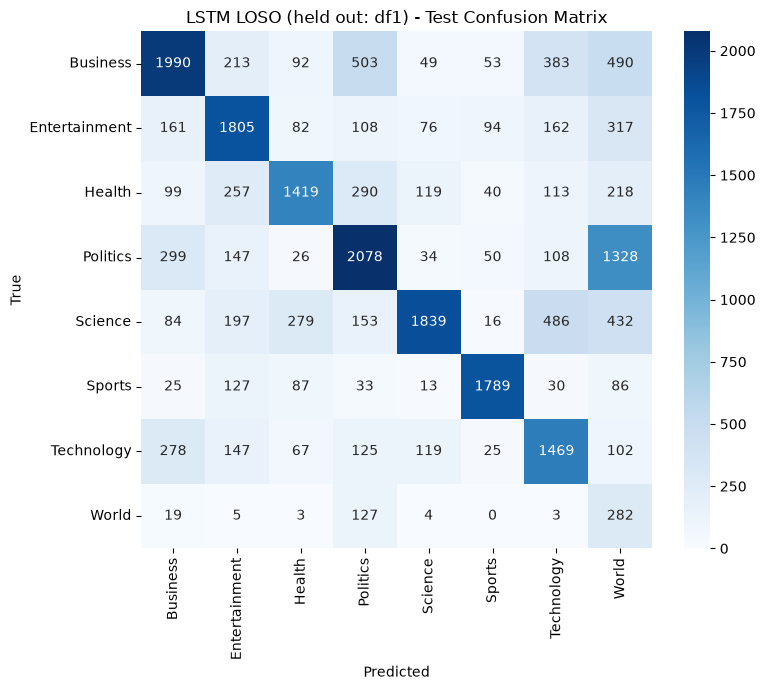

loso_df1: macro_f1=0.5759 (n_test=21654, classes=8, train_time=1077.6s)


Epoch 1/15


2674/2674 - 1285s - 481ms/step - accuracy: 0.7383 - loss: 0.8163 - val_accuracy: 0.8088 - val_loss: 0.5856


Epoch 2/15


2674/2674 - 1052s - 393ms/step - accuracy: 0.8306 - loss: 0.5417 - val_accuracy: 0.8223 - val_loss: 0.5553


Epoch 3/15


2674/2674 - 5543s - 2s/step - accuracy: 0.8561 - loss: 0.4511 - val_accuracy: 0.8233 - val_loss: 0.5704


Epoch 4/15


2674/2674 - 1124s - 421ms/step - accuracy: 0.8790 - loss: 0.3737 - val_accuracy: 0.8177 - val_loss: 0.6323


Epoch 5/15


2674/2674 - 1069s - 400ms/step - accuracy: 0.8982 - loss: 0.3083 - val_accuracy: 0.8159 - val_loss: 0.7027


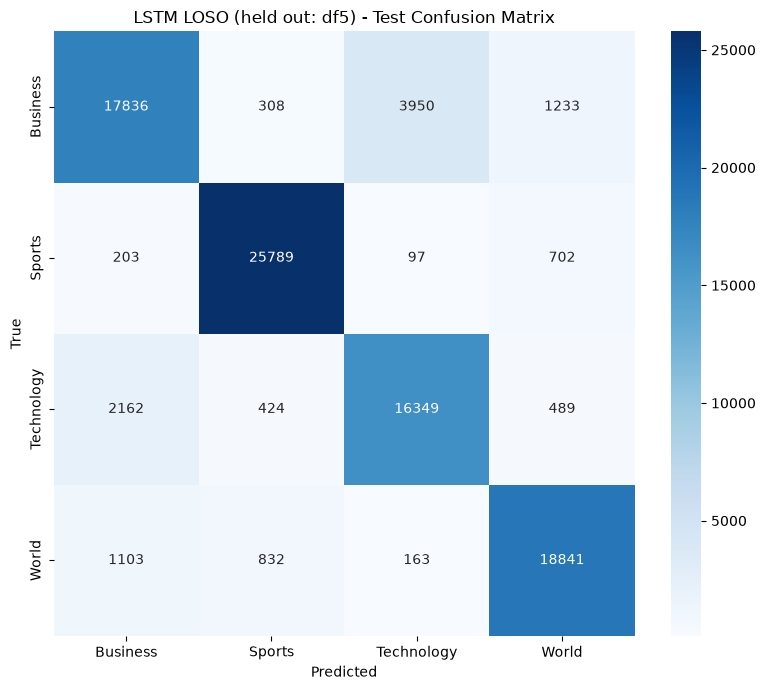

loso_df5: macro_f1=0.7444 (n_test=119911, classes=4, train_time=10074.2s)


,held_out_source,n_train,n_test,n_classes_present,macro_f1,train_time_sec
0,df1,254600,21654,8,0.575853,1077.643963
1,df5,171082,119911,4,0.744401,10074.191532


In [2]:
loso_results = []

for held_out in SOURCES:
    tf.keras.utils.set_random_seed(SEED)

    fold_dir = SPLITS_ROOT / f"loso_{held_out}"
    train_df = pd.read_csv(fold_dir / "train.csv")
    val_df = pd.read_csv(fold_dir / "val.csv")
    test_df = pd.read_csv(fold_dir / "test.csv")

    y_train = label_encoder.transform(train_df["category"])
    y_val = label_encoder.transform(val_df["category"])
    y_test = label_encoder.transform(test_df["category"])
    present_classes = np.unique(y_test)
    present_class_names = label_encoder.inverse_transform(present_classes).tolist()

    tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
    tokenizer.fit_on_texts(train_df["text"])

    train_token_counts = train_df["text"].fillna("").astype(str).str.split().str.len()
    p95 = int(np.percentile(train_token_counts, 95))
    max_len = int(np.clip(p95, 20, 200))

    def to_padded(texts, max_len=max_len, tok=tokenizer):
        seqs = tok.texts_to_sequences(texts)
        return pad_sequences(seqs, maxlen=max_len, padding="post", truncating="post")

    X_train = to_padded(train_df["text"])
    X_val = to_padded(val_df["text"])
    X_test = to_padded(test_df["text"])

    model = models.Sequential([
        layers.Input(shape=(max_len,)),
        layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True),
        layers.Bidirectional(
            layers.LSTM(LSTM_UNITS, dropout=DROPOUT, recurrent_dropout=RECURRENT_DROPOUT, return_sequences=False)
        ),
        layers.Dropout(DROPOUT),
        layers.Dense(64, activation="relu"),
        layers.Dropout(DROPOUT),
        layers.Dense(len(LABEL_ORDER), activation="softmax"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    fold_weights_dir = WEIGHTS_ROOT / f"loso_{held_out}" / "lstm"
    fold_weights_dir.mkdir(parents=True, exist_ok=True)

    callback_list = [
        callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        callbacks.ModelCheckpoint(
            filepath=str(fold_weights_dir / "lstm_model.keras"),
            monitor="val_loss",
            save_best_only=True,
        ),
    ]

    start_time = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callback_list,
        verbose=2,
    )
    train_time_sec = time.time() - start_time

    model = tf.keras.models.load_model(fold_weights_dir / "lstm_model.keras")

    inf_start = time.time()
    y_pred_probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
    inf_time_sec = time.time() - inf_start
    y_pred = np.argmax(y_pred_probs, axis=1)

    macro_f1 = f1_score(y_test, y_pred, labels=present_classes, average="macro", zero_division=0)
    report_dict = classification_report(
        y_test, y_pred, labels=present_classes, target_names=present_class_names,
        output_dict=True, zero_division=0,
    )

    cm = confusion_matrix(y_test, y_pred, labels=present_classes)
    plt.figure(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=present_class_names, yticklabels=present_class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"LSTM LOSO (held out: {held_out}) - Test Confusion Matrix")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"{held_out}_confusion_matrix.png", dpi=150)
    plt.show()
    plt.close()

    with open(fold_weights_dir / "tokenizer.pkl", "wb") as f:
        pickle.dump(tokenizer, f)

    config = {
        "max_len": max_len,
        "vocab_size": VOCAB_SIZE,
        "embedding_dim": EMBEDDING_DIM,
        "lstm_units": LSTM_UNITS,
        "batch_size": BATCH_SIZE,
        "epochs_planned": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "epochs_trained": len(history.history["loss"]),
    }
    with open(fold_weights_dir / "config.json", "w") as f:
        json.dump(config, f, indent=2)

    metrics = {
        "model_family": "lstm",
        "model_name": "bilstm-scratch-embed-loso",
        "run_timestamp": pd.Timestamp.now("UTC").isoformat(),
        "label_order": LABEL_ORDER,
        "loso_held_out_source": held_out,
        "loso_classes_present": present_class_names,
        "config": config,
        "train": {
            "n_train": len(train_df),
            "n_val": len(val_df),
            "train_time_sec": train_time_sec,
            "epochs_trained": len(history.history["loss"]),
            "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
        },
        "test": {
            "n_test": len(test_df),
            "n_classes_present": len(present_classes),
            "macro_f1": macro_f1,
            "per_class": {name: report_dict[name] for name in present_class_names},
            "confusion_matrix": cm.tolist(),
            "inf_time_sec": inf_time_sec,
            "inference_time_ms_per_sample": inf_time_sec / len(test_df) * 1000,
        },
        "environment": {
            "framework": "tensorflow",
            "framework_version": tf.__version__,
            "device": "GPU" if tf.config.list_physical_devices("GPU") else "CPU",
            "seed": SEED,
        },
    }

    with open(RESULTS_DIR / f"{held_out}_metrics.json", "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

    loso_results.append({
        "held_out_source": held_out,
        "n_train": len(train_df),
        "n_test": len(test_df),
        "n_classes_present": len(present_classes),
        "macro_f1": macro_f1,
        "train_time_sec": train_time_sec,
    })
    print(f"loso_{held_out}: macro_f1={macro_f1:.4f} (n_test={len(test_df)}, classes={len(present_classes)}, train_time={train_time_sec:.1f}s)")

loso_results_df = pd.DataFrame(loso_results)
loso_results_df

In [3]:
loso_results_df.to_csv(RESULTS_DIR / "lstm_loso_summary.csv", index=False, encoding="utf-8")
print("Wrote:", (RESULTS_DIR / "lstm_loso_summary.csv").resolve())
print("\nIn-distribution LSTM_a test accuracy for comparison: 0.8333 (see results/lstm/LSTM_a_metrics.json)")
print("Mean LOSO macro_f1:", loso_results_df["macro_f1"].mean())

Wrote: D:\UoL\Sem2\mnu2\results\lstm\loso\lstm_loso_summary.csv

In-distribution LSTM_a test accuracy for comparison: 0.8333 (see results/lstm/LSTM_a_metrics.json)
Mean LOSO macro_f1: 0.6601273886701664
